In [1]:
import pandas as pd
import numpy as np
import random
import time
import pickle
import os
import sys

sys.path.append(os.path.abspath('..'))

from sklearn.model_selection import StratifiedKFold
from IPython.display import display

from utils.graphs import plot_confusion_matrix
from utils.util import evaluate_predictions, cross_evaluate_adversarial_learning
from utils.models import available_models, get_model


print("Pandas version: {}".format(pd.__version__))
print("NumPy version: {}".format(np.__version__))

seed = 42
np.random.seed(seed)
random.seed(seed)

Pandas version: 2.2.2
NumPy version: 2.0.1


# Load the data

In [2]:
df = pd.read_parquet("../../data/CICIDS2017_improved/clean/tuesday-latest.parquet")

adv_files = [
    "patator-ssh-cic.parquet",
    "patator-versions-ssh-cic.parquet",
    "patator-network-ssh-cic.parquet",
    "hydra-ssh-cic.parquet",
    "medusa-ssh-cic.parquet",
]
df_adv = pd.concat([pd.read_parquet(f"../../data/concap/clean/{f}") for f in adv_files], ignore_index=True)
df_adv.scenario.value_counts()

scenario
patator_ssh_cic_T5                     3400
patator_ssh_cic_T10                    3400
patator_ssh_cic_T1                     3400
medusa_ssh_cic_ubuntu24_T10_default    1151
medusa_ssh_cic_ubuntu24_T10_long       1151
medusa_ssh_cic_ubuntu20_T10_long       1149
medusa_ssh_cic_ubuntu18_T10_long       1149
medusa_ssh_cic_ubuntu20_T10_min        1148
medusa_ssh_cic_ubuntu20_T10_default    1148
medusa_ssh_cic_ubuntu18_T10_default    1147
medusa_ssh_cic_ubuntu18_T10_min        1147
medusa_ssh_cic_ubuntu24_T10_min        1145
hydra_ssh_cic_ubuntu20_T10              758
hydra_ssh_cic_ubuntu24_T10              755
hydra_ssh_cic_ubuntu18_T10              727
patator_ssh_cic_D10_L0_C0_Dup0          680
patator_ssh_cic_D25_L5_C5_Dup5          680
patator_ssh_cic_D100_L0_C5_Dup5         680
patator_ssh_cic_D10_L5_C0_Dup5          680
patator_ssh_cic_D10_L5_C0_Dup0          680
patator_ssh_cic_D25_L0_C5_Dup0          680
patator_ssh_cic_D100_L5_C0_Dup0         680
patator_ssh_cic_D100_L5

# Prepare for evaluation

In [3]:
result_dir = "../results/cicids2017-latest/defense"
if not os.path.exists(result_dir):
    os.makedirs(result_dir)

In [4]:
train_scenarios = [ # train on scenarios with single and 10 threads, test on 5 threads.
    'patator-ssh-cic-t1',
    'patator-ssh-cic-t10',
    # 'patator-ssh-cic-t5',
    'patator-ssh-cic-t10-p-rl1',
    'patator-ssh-cic-t10-p',
    # 'patator-ssh-cic-t5-p',
    # 'patator-ssh-cic-t5-p-rl1',
    'patator-ssh-cic-t1-p',
    'patator-ssh-cic-t1-p-rl1'
]
df_adv['scenario'] = df_adv.scenario.map(lambda x: x.replace("_", "-").lower())
X_adv, y_adv, groups = df_adv.drop(columns=["Label", "scenario"]), pd.Series(np.ones(df_adv.shape[0])), df_adv["scenario"]
X_adv_train, y_adv_train, groups_train = X_adv[df_adv.scenario.isin(train_scenarios)], y_adv[df_adv.scenario.isin(train_scenarios)], groups[df_adv.scenario.isin(train_scenarios)]
X_adv_test, y_adv_test, groups_test = X_adv[~df_adv.scenario.isin(train_scenarios)], y_adv[~df_adv.scenario.isin(train_scenarios)], groups[~df_adv.scenario.isin(train_scenarios)]

In [5]:
groups_train.value_counts()

scenario
patator-ssh-cic-t10          3400
patator-ssh-cic-t1           3400
patator-ssh-cic-t10-p-rl1     680
patator-ssh-cic-t10-p         680
patator-ssh-cic-t1-p          578
patator-ssh-cic-t1-p-rl1      578
Name: count, dtype: int64

In [6]:
# We are not interested in the FTP bruteforce samples from CICIDS2017
df = df[df['Label'] != 'FTP-Patator']
X, y = df.drop(columns=["Label"]), df["Label"].map(lambda x: 0 if x == "BENIGN" else 1)
del df

# Adversarial training as Defense

We evaluate adversarial learning as potential defense against the true-problem space attacks. The adversarial perturbations are split into training and test set. The training set is added to training in each loop of the cross-validation. The test set is used to evaluate if the defense is successful.

Evaluating model: decision_tree


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,6.861998,0.111323,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11684}",253508.000000,"[[241824, 0], [0, 11684]]",0.031081,0.998311,0.996627,1.000000,0.999967,1.000000,"{0: 60456, 1: 593}",61049.000000,"[[60456, 0], [2, 591]]"
1,7.054434,0.306934,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.077981,1.000000,1.000000,1.000000,1.000000,1.000000,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
2,9.066460,0.108699,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.032085,0.994924,0.993243,0.996610,0.999902,0.999967,"{0: 60456, 1: 592}",61048.000000,"[[60454, 2], [4, 588]]"
3,8.882309,0.350955,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.036036,0.995781,0.996622,0.994941,0.999918,0.999950,"{0: 60456, 1: 592}",61048.000000,"[[60453, 3], [2, 590]]"
4,9.222146,0.113657,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.033622,0.995766,0.993243,0.998302,0.999918,0.999983,"{0: 60456, 1: 592}",61048.000000,"[[60455, 1], [4, 588]]"
mean,8.217470,0.198314,1.0,1.0,1.0,1.0,1.0,NaN,253508.800000,NaN,0.042161,0.996956,0.995947,0.997971,0.999941,0.999980,NaN,61048.200000,NaN
std,1.157813,0.120274,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.020111,0.002123,0.002827,0.002201,0.000041,0.000022,NaN,0.447214,NaN


Aggregated test confusion matrix:


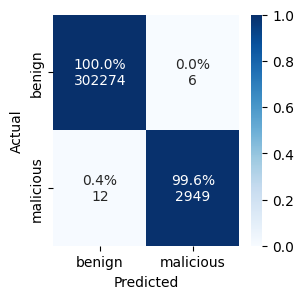

Training time for on all data: 7.8344

Evaluating model: decision_tree_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,6.762372,0.180579,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11684}",253508.000000,"[[241824, 0], [0, 11684]]",0.048527,0.999156,0.998314,1.000000,0.999984,1.000000,"{0: 60456, 1: 593}",61049.000000,"[[60456, 0], [1, 592]]"
1,7.984066,0.173486,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.043080,1.000000,1.000000,1.000000,1.000000,1.000000,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
2,9.985392,0.171970,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.047286,0.994093,0.994932,0.993255,0.999885,0.999934,"{0: 60456, 1: 592}",61048.000000,"[[60452, 4], [3, 589]]"
3,9.748179,0.561900,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.138121,0.996616,0.994932,0.998305,0.999934,0.999983,"{0: 60456, 1: 592}",61048.000000,"[[60455, 1], [3, 589]]"
4,9.249868,0.158277,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.049192,0.995766,0.993243,0.998302,0.999918,0.999983,"{0: 60456, 1: 592}",61048.000000,"[[60455, 1], [4, 588]]"
mean,8.745976,0.249243,1.0,1.0,1.0,1.0,1.0,NaN,253508.800000,NaN,0.065241,0.997126,0.996284,0.997972,0.999944,0.999980,NaN,61048.200000,NaN
std,1.351819,0.174967,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.040810,0.002434,0.002776,0.002770,0.000047,0.000027,NaN,0.447214,NaN


Aggregated test confusion matrix:


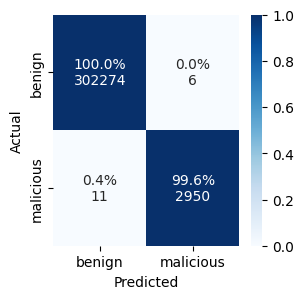

Training time for on all data: 8.6144

Evaluating model: logistic_regression


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,2.766727,0.367452,0.997220,0.997775,0.996666,0.999744,0.999839,"{0.0: 241824, 1.0: 11684}",253508.000000,"[[241785, 39], [26, 11658]]",0.077150,0.986577,0.991568,0.981636,0.999738,0.999818,"{0: 60456, 1: 593}",61049.000000,"[[60445, 11], [5, 588]]"
1,3.025206,0.408242,0.997306,0.998117,0.996497,0.999751,0.999830,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241783, 41], [22, 11663]]",0.056388,0.988215,0.991554,0.984899,0.999771,0.999851,"{0: 60456, 1: 592}",61048.000000,"[[60447, 9], [5, 587]]"
2,2.843247,0.376863,0.997305,0.997518,0.997092,0.999751,0.999859,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241790, 34], [29, 11656]]",0.071215,0.980688,0.986486,0.974958,0.999623,0.999752,"{0: 60456, 1: 592}",61048.000000,"[[60441, 15], [8, 584]]"
3,3.167551,0.310759,0.997349,0.998203,0.996497,0.999755,0.999830,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241783, 41], [21, 11664]]",0.050235,0.983221,0.989865,0.976667,0.999672,0.999768,"{0: 60456, 1: 592}",61048.000000,"[[60442, 14], [6, 586]]"
4,3.239228,0.221000,0.996706,0.997090,0.996323,0.999696,0.999822,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241781, 43], [34, 11651]]",0.050082,0.982278,0.983108,0.981450,0.999656,0.999818,"{0: 60456, 1: 592}",61048.000000,"[[60445, 11], [10, 582]]"
mean,3.008392,0.336863,0.997177,0.997741,0.996615,0.999740,0.999836,NaN,253508.800000,NaN,0.061014,0.984196,0.988516,0.979922,0.999692,0.999802,NaN,61048.200000,NaN
std,0.202839,0.073716,0.000267,0.000455,0.000293,0.000025,0.000014,NaN,0.447214,NaN,0.012465,0.003113,0.003665,0.004040,0.000061,0.000041,NaN,0.447214,NaN


Aggregated test confusion matrix:


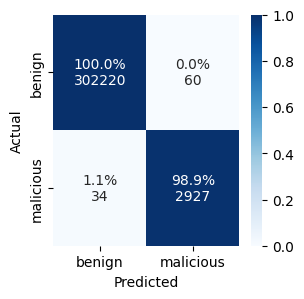

Training time for on all data: 1.9889

Evaluating model: logistic_regression_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,3.819054,0.289351,0.997220,0.997775,0.996666,0.999744,0.999839,"{0.0: 241824, 1.0: 11684}",253508.000000,"[[241785, 39], [26, 11658]]",0.066611,0.986577,0.991568,0.981636,0.999738,0.999818,"{0: 60456, 1: 593}",61049.000000,"[[60445, 11], [5, 588]]"
1,3.402215,0.407156,0.997306,0.998117,0.996497,0.999751,0.999830,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241783, 41], [22, 11663]]",0.060438,0.988215,0.991554,0.984899,0.999771,0.999851,"{0: 60456, 1: 592}",61048.000000,"[[60447, 9], [5, 587]]"
2,2.566093,0.435124,0.997305,0.997518,0.997092,0.999751,0.999859,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241790, 34], [29, 11656]]",0.078427,0.980688,0.986486,0.974958,0.999623,0.999752,"{0: 60456, 1: 592}",61048.000000,"[[60441, 15], [8, 584]]"
3,3.382320,0.365938,0.997349,0.998203,0.996497,0.999755,0.999830,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241783, 41], [21, 11664]]",0.065780,0.983221,0.989865,0.976667,0.999672,0.999768,"{0: 60456, 1: 592}",61048.000000,"[[60442, 14], [6, 586]]"
4,2.924378,0.429629,0.996706,0.997090,0.996323,0.999696,0.999822,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241781, 43], [34, 11651]]",0.070246,0.982278,0.983108,0.981450,0.999656,0.999818,"{0: 60456, 1: 592}",61048.000000,"[[60445, 11], [10, 582]]"
mean,3.218812,0.385440,0.997177,0.997741,0.996615,0.999740,0.999836,NaN,253508.800000,NaN,0.068300,0.984196,0.988516,0.979922,0.999692,0.999802,NaN,61048.200000,NaN
std,0.483062,0.060221,0.000267,0.000455,0.000293,0.000025,0.000014,NaN,0.447214,NaN,0.006659,0.003113,0.003665,0.004040,0.000061,0.000041,NaN,0.447214,NaN


Aggregated test confusion matrix:


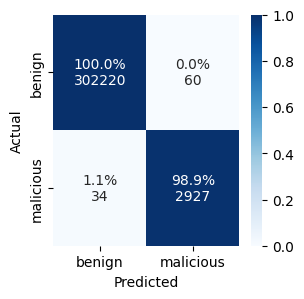

Training time for on all data: 2.3711

Evaluating model: one_rule


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,18.508356,0.072045,0.544891,0.999914,0.374479,0.923016,0.919301,"{0.0: 241824, 1.0: 11684}",253508.000000,"[[222309, 19515], [1, 11683]]",0.018268,0.194267,1.000000,0.107583,0.919425,0.918635,"{0: 60456, 1: 593}",61049.000000,"[[55537, 4919], [0, 593]]"
1,23.612415,0.073146,0.544455,0.999914,0.374068,0.922875,0.919152,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[222273, 19551], [1, 11684]]",0.020489,0.195154,1.000000,0.108128,0.920014,0.919231,"{0: 60456, 1: 592}",61048.000000,"[[55573, 4883], [0, 592]]"
2,18.809685,0.073682,0.544037,0.999914,0.373673,0.922744,0.919015,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[222240, 19584], [1, 11684]]",0.023047,0.196221,1.000000,0.108784,0.920554,0.919776,"{0: 60456, 1: 592}",61048.000000,"[[55606, 4850], [0, 592]]"
3,23.914859,0.074640,0.545331,0.999914,0.374896,0.923147,0.919437,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[222342, 19482], [1, 11684]]",0.018443,0.192960,1.000000,0.106782,0.918884,0.918089,"{0: 60456, 1: 592}",61048.000000,"[[55504, 4952], [0, 592]]"
4,20.148124,0.072052,0.543817,1.000000,0.373454,0.922669,0.918933,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[222220, 19604], [0, 11685]]",0.019688,0.196574,0.998311,0.109020,0.920866,0.920107,"{0: 60456, 1: 592}",61048.000000,"[[55626, 4830], [1, 591]]"
mean,20.998688,0.073113,0.544506,0.999932,0.374114,0.922890,0.919168,NaN,253508.800000,NaN,0.019987,0.195035,0.999662,0.108059,0.919949,0.919168,NaN,61048.200000,NaN
std,2.600604,0.001110,0.000618,0.000038,0.000587,0.000195,0.000206,NaN,0.447214,NaN,0.001940,0.001474,0.000755,0.000910,0.000809,0.000822,NaN,0.447214,NaN


Aggregated test confusion matrix:


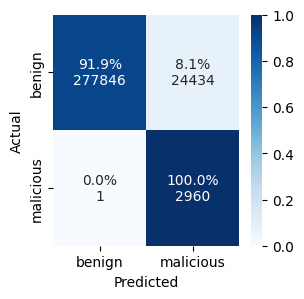

Training time for on all data: 0.2244

Evaluating model: one_rule_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,18.336227,0.465422,0.544891,0.999914,0.374479,0.923016,0.919301,"{0.0: 241824, 1.0: 11684}",253508.000000,"[[222309, 19515], [1, 11683]]",0.105834,0.194267,1.000000,0.107583,0.919425,0.918635,"{0: 60456, 1: 593}",61049.000000,"[[55537, 4919], [0, 593]]"
1,18.542473,0.156834,0.544455,0.999914,0.374068,0.922875,0.919152,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[222273, 19551], [1, 11684]]",0.044150,0.195154,1.000000,0.108128,0.920014,0.919231,"{0: 60456, 1: 592}",61048.000000,"[[55573, 4883], [0, 592]]"
2,19.165437,0.146838,0.544037,0.999914,0.373673,0.922744,0.919015,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[222240, 19584], [1, 11684]]",0.039756,0.196221,1.000000,0.108784,0.920554,0.919776,"{0: 60456, 1: 592}",61048.000000,"[[55606, 4850], [0, 592]]"
3,20.453480,0.156597,0.545331,0.999914,0.374896,0.923147,0.919437,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[222342, 19482], [1, 11684]]",0.039974,0.192960,1.000000,0.106782,0.918884,0.918089,"{0: 60456, 1: 592}",61048.000000,"[[55504, 4952], [0, 592]]"
4,19.160781,0.301214,0.543817,1.000000,0.373454,0.922669,0.918933,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[222220, 19604], [0, 11685]]",0.029698,0.196574,0.998311,0.109020,0.920866,0.920107,"{0: 60456, 1: 592}",61048.000000,"[[55626, 4830], [1, 591]]"
mean,19.131680,0.245381,0.544506,0.999932,0.374114,0.922890,0.919168,NaN,253508.800000,NaN,0.051882,0.195035,0.999662,0.108059,0.919949,0.919168,NaN,61048.200000,NaN
std,0.825992,0.138717,0.000618,0.000038,0.000587,0.000195,0.000206,NaN,0.447214,NaN,0.030625,0.001474,0.000755,0.000910,0.000809,0.000822,NaN,0.447214,NaN


Aggregated test confusion matrix:


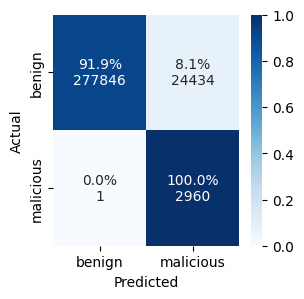

Best feature index: 8
Training time for on all data: 23.8049

Evaluating model: random_forest


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,38.972439,0.499557,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11684}",253508.000000,"[[241824, 0], [0, 11684]]",0.115116,0.999156,0.998314,1.0,0.999984,1.0,"{0: 60456, 1: 593}",61049.000000,"[[60456, 0], [1, 592]]"
1,35.826055,0.720553,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.158146,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
2,37.568459,0.500902,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.119128,0.997460,0.994932,1.0,0.999951,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [3, 589]]"
3,35.695413,0.871408,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.185609,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
4,36.598228,0.625790,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.108415,0.998308,0.996622,1.0,0.999967,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [2, 590]]"
mean,36.932119,0.643642,1.0,1.0,1.0,1.0,1.0,NaN,253508.800000,NaN,0.137283,0.998985,0.997974,1.0,0.999980,1.0,NaN,61048.200000,NaN
std,1.363097,0.157517,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.033260,0.001104,0.002203,0.0,0.000021,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


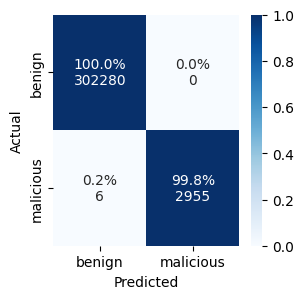

Training time for on all data: 42.2921

Evaluating model: random_forest_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,37.521587,0.917490,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11684}",253508.000000,"[[241824, 0], [0, 11684]]",0.257403,0.999156,0.998314,1.0,0.999984,1.0,"{0: 60456, 1: 593}",61049.000000,"[[60456, 0], [1, 592]]"
1,45.762419,0.659892,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.164064,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
2,56.039637,0.551737,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.123392,0.997460,0.994932,1.0,0.999951,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [3, 589]]"
3,46.415306,0.688387,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.143765,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
4,51.639002,0.558577,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.120554,0.998308,0.996622,1.0,0.999967,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [2, 590]]"
mean,47.475590,0.675217,1.0,1.0,1.0,1.0,1.0,NaN,253508.800000,NaN,0.161836,0.998985,0.997974,1.0,0.999980,1.0,NaN,61048.200000,NaN
std,6.960931,0.148288,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.056229,0.001104,0.002203,0.0,0.000021,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


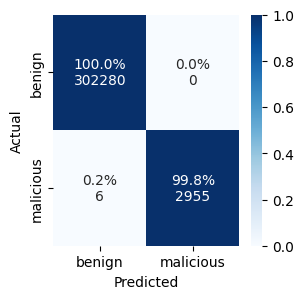

Training time for on all data: 52.3602

Evaluating model: neural_network


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,21.807231,0.845345,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11684}",253508.000000,"[[241824, 0], [0, 11684]]",0.259910,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 593}",61049.000000,"[[60456, 0], [0, 593]]"
1,22.999848,0.602129,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.102237,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
2,22.609887,0.599033,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.130045,0.997460,0.994932,1.0,0.999951,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [3, 589]]"
3,22.792711,0.651332,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.139663,0.999155,0.998311,1.0,0.999984,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [1, 591]]"
4,22.650196,0.656109,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.136444,0.999155,0.998311,1.0,0.999984,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [1, 591]]"
mean,22.571975,0.670789,1.0,1.0,1.0,1.0,1.0,NaN,253508.800000,NaN,0.153660,0.999154,0.998311,1.0,0.999984,1.0,NaN,61048.200000,NaN
std,0.453924,0.101152,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.061203,0.001037,0.002069,0.0,0.000020,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


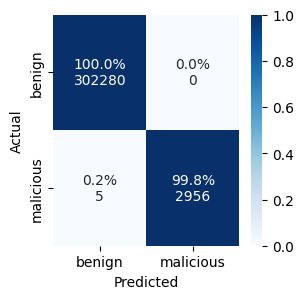

Training time for on all data: 21.6185

Evaluating model: neural_network_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,18.006885,1.478120,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11684}",253508.000000,"[[241824, 0], [0, 11684]]",0.189599,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 593}",61049.000000,"[[60456, 0], [0, 593]]"
1,17.064503,0.511045,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.126606,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
2,21.291353,0.561914,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.114154,0.998308,0.996622,1.0,0.999967,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [2, 590]]"
3,21.509479,0.497699,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.094147,0.999155,0.998311,1.0,0.999984,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [1, 591]]"
4,19.372582,1.007821,1.0,1.0,1.0,1.0,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.176398,0.999155,0.998311,1.0,0.999984,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [1, 591]]"
mean,19.448960,0.811320,1.0,1.0,1.0,1.0,1.0,NaN,253508.800000,NaN,0.140181,0.999323,0.998649,1.0,0.999987,1.0,NaN,61048.200000,NaN
std,1.962855,0.428358,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.041032,0.000708,0.001413,0.0,0.000014,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


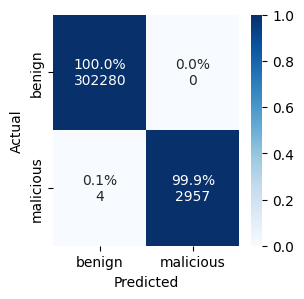

Training time for on all data: 19.7996

Evaluating model: support_vector_machine


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,10.867202,6.399083,0.998759,0.998374,0.999143,0.999886,0.999959,"{0.0: 241824, 1.0: 11684}",253508.000000,"[[241814, 10], [19, 11665]]",1.660352,0.994924,0.991568,0.998302,0.999902,0.999983,"{0: 60456, 1: 593}",61049.000000,"[[60455, 1], [5, 588]]"
1,14.550315,7.924786,0.998587,0.998032,0.999143,0.999870,0.999959,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241814, 10], [23, 11662]]",1.718663,0.994924,0.993243,0.996610,0.999902,0.999967,"{0: 60456, 1: 592}",61048.000000,"[[60454, 2], [4, 588]]"
2,12.324082,6.773771,0.999101,0.998631,0.999572,0.999917,0.999979,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241819, 5], [16, 11669]]",1.756133,0.994073,0.991554,0.996604,0.999885,0.999967,"{0: 60456, 1: 592}",61048.000000,"[[60454, 2], [5, 587]]"
3,12.870776,7.156491,0.998844,0.998117,0.999571,0.999893,0.999979,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241819, 5], [22, 11663]]",1.671491,0.993232,0.991554,0.994915,0.999869,0.999950,"{0: 60456, 1: 592}",61048.000000,"[[60453, 3], [5, 587]]"
4,11.640902,6.873613,0.998887,0.998545,0.999229,0.999897,0.999963,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241815, 9], [17, 11668]]",1.485547,0.991525,0.988176,0.994898,0.999836,0.999950,"{0: 60456, 1: 592}",61048.000000,"[[60453, 3], [7, 585]]"
mean,12.450655,7.025549,0.998836,0.998340,0.999332,0.999893,0.999968,NaN,253508.800000,NaN,1.658437,0.993736,0.991219,0.996266,0.999879,0.999964,NaN,61048.200000,NaN
std,1.393208,0.571119,0.000188,0.000261,0.000222,0.000017,0.000011,NaN,0.447214,NaN,0.103967,0.001421,0.001851,0.001421,0.000027,0.000014,NaN,0.447214,NaN


Aggregated test confusion matrix:


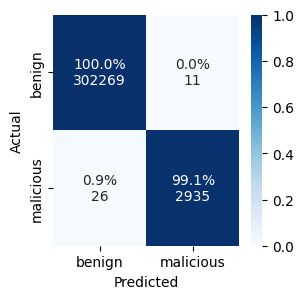

Training time for on all data: 10.2113

Evaluating model: support_vector_machine_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,13.901925,6.569761,0.998759,0.998374,0.999143,0.999886,0.999959,"{0.0: 241824, 1.0: 11684}",253508.000000,"[[241814, 10], [19, 11665]]",1.554489,0.994924,0.991568,0.998302,0.999902,0.999983,"{0: 60456, 1: 593}",61049.000000,"[[60455, 1], [5, 588]]"
1,10.223208,7.073797,0.998587,0.998032,0.999143,0.999870,0.999959,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241814, 10], [23, 11662]]",1.654801,0.994924,0.993243,0.996610,0.999902,0.999967,"{0: 60456, 1: 592}",61048.000000,"[[60454, 2], [4, 588]]"
2,13.623707,6.767243,0.999101,0.998631,0.999572,0.999917,0.999979,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241819, 5], [16, 11669]]",1.658439,0.994073,0.991554,0.996604,0.999885,0.999967,"{0: 60456, 1: 592}",61048.000000,"[[60454, 2], [5, 587]]"
3,11.878628,6.691289,0.998844,0.998117,0.999571,0.999893,0.999979,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241819, 5], [22, 11663]]",1.574594,0.993232,0.991554,0.994915,0.999869,0.999950,"{0: 60456, 1: 592}",61048.000000,"[[60453, 3], [5, 587]]"
4,15.526731,7.385504,0.998887,0.998545,0.999229,0.999897,0.999963,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241815, 9], [17, 11668]]",1.590913,0.991525,0.988176,0.994898,0.999836,0.999950,"{0: 60456, 1: 592}",61048.000000,"[[60453, 3], [7, 585]]"
mean,13.030840,6.897519,0.998836,0.998340,0.999332,0.999893,0.999968,NaN,253508.800000,NaN,1.606647,0.993736,0.991219,0.996266,0.999879,0.999964,NaN,61048.200000,NaN
std,2.034093,0.330201,0.000188,0.000261,0.000222,0.000017,0.000011,NaN,0.447214,NaN,0.047425,0.001421,0.001851,0.001421,0.000027,0.000014,NaN,0.447214,NaN


Aggregated test confusion matrix:


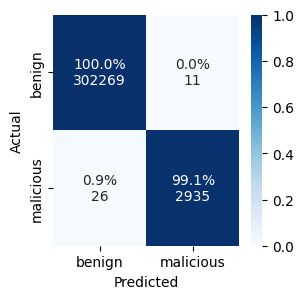

Training time for on all data: 10.1233



In [7]:
# Split the data in train and test
# Do Stratified K-fold cross validation (n=5), afterwards train model on all data and save to disk. 
s_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

models = {}

for model_name in available_models:
    print("Evaluating model: {}".format(model_name))

    # Cross evaluate the selected model
    ml_pipeline = get_model(model_name)
    results = cross_evaluate_adversarial_learning(ml_pipeline, X, y, X_adv_train, y_adv_train, s_kfold, metrics_func=evaluate_predictions, n_jobs=5)
    results.to_csv(f"{result_dir}/{model_name}_results.csv", index=True)
    results.to_pickle(f"{result_dir}/{model_name}_results.p")
    display(results)

    # Plot the aggregated confusion matrix over all test folds
    print("Aggregated test confusion matrix:")
    agg_conf_matrix = np.sum([np.array(matrix) for matrix in results['test_conf_matrix'].dropna()], axis=0)
    plt = plot_confusion_matrix(agg_conf_matrix, figsize=(3,3))
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.png", format='png', bbox_inches='tight')
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.eps", format='eps', bbox_inches='tight')
    plt.show()

    # Train the model on all data
    start_time = time.time()
    if model_name == 'one_rule':
        # Prevent information leakage by using the best rule from the cross evaluation
        models[model_name] = ml_pipeline.fit(pd.concat([X, X_adv_train]), pd.concat([y, y_adv_train]), clf__feature_idx=8)
    else:
        models[model_name] = ml_pipeline.fit(pd.concat([X, X_adv_train]), pd.concat([y, y_adv_train]))
    training_time = time.time() - start_time
    print("Training time for on all data: {:.4f}".format(training_time))

    # Save the model
    f = open(f"{result_dir}/{model_name}.p", "wb")
    pickle.dump(models[model_name], f)
    f.close()
    print()

Evaluating model: hist_gradient_boosting


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,21.773081,2.436917,0.999957,0.999914,1.0,0.999996,1.0,"{0.0: 241824, 1.0: 11684}",253508.000000,"[[241824, 0], [1, 11683]]",0.424904,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 593}",61049.000000,"[[60456, 0], [0, 593]]"
1,25.233759,1.472100,1.000000,1.000000,1.0,1.000000,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.339988,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
2,17.176262,2.191319,1.000000,1.000000,1.0,1.000000,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.650964,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
3,20.178588,2.279914,1.000000,1.000000,1.0,1.000000,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.684579,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
4,25.201482,1.521360,1.000000,1.000000,1.0,1.000000,1.0,"{0.0: 241824, 1.0: 11685}",253509.000000,"[[241824, 0], [0, 11685]]",0.190539,0.997460,0.994932,1.0,0.999951,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [3, 589]]"
mean,21.912634,1.980322,0.999991,0.999983,1.0,0.999999,1.0,NaN,253508.800000,NaN,0.458195,0.999492,0.998986,1.0,0.999990,1.0,NaN,61048.200000,NaN
std,3.438968,0.450469,0.000019,0.000038,0.0,0.000002,0.0,NaN,0.447214,NaN,0.209243,0.001136,0.002266,0.0,0.000022,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


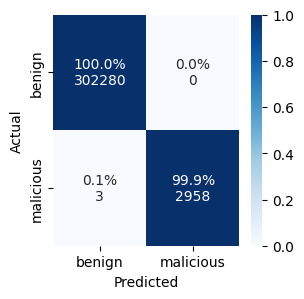

Training time for on all data: 8.7056



In [7]:
# Split the data in train and test
# Do Stratified K-fold cross validation (n=5), afterwards train model on all data and save to disk. 
s_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

models = {}

for model_name in ['hist_gradient_boosting']:
    print("Evaluating model: {}".format(model_name))

    # Cross evaluate the selected model
    ml_pipeline = get_model(model_name)
    results = cross_evaluate_adversarial_learning(ml_pipeline, X, y, X_adv_train, y_adv_train, s_kfold, metrics_func=evaluate_predictions, n_jobs=5)
    results.to_csv(f"{result_dir}/{model_name}_results.csv", index=True)
    results.to_pickle(f"{result_dir}/{model_name}_results.p")
    display(results)

    # Plot the aggregated confusion matrix over all test folds
    print("Aggregated test confusion matrix:")
    agg_conf_matrix = np.sum([np.array(matrix) for matrix in results['test_conf_matrix'].dropna()], axis=0)
    plt = plot_confusion_matrix(agg_conf_matrix, figsize=(3,3))
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.png", format='png', bbox_inches='tight')
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.eps", format='eps', bbox_inches='tight')
    plt.show()

    # Train the model on all data
    start_time = time.time()
    if model_name == 'one_rule':
        # Prevent information leakage by using the best rule from the cross evaluation
        models[model_name] = ml_pipeline.fit(pd.concat([X, X_adv_train]), pd.concat([y, y_adv_train]), clf__feature_idx=8)
    else:
        models[model_name] = ml_pipeline.fit(pd.concat([X, X_adv_train]), pd.concat([y, y_adv_train]))
    training_time = time.time() - start_time
    print("Training time for on all data: {:.4f}".format(training_time))

    # Save the model
    f = open(f"{result_dir}/{model_name}.p", "wb")
    pickle.dump(models[model_name], f)
    f.close()
    print()

# Adversarial Evaluation

In [8]:
baseline_dir = result_dir

In [9]:
for model_name in available_models:
    print("Evaluating model: {}".format(model_name))
    with open(f"{baseline_dir}/{model_name}.p", "rb") as f:
        ml_pipeline = pickle.load(f)
        recall_before_attack = pd.read_csv(f"{baseline_dir}/{model_name}_results.csv", index_col=0).loc['mean', 'test_recall']
        results = []
        
        for scenario in groups_train.unique():
            X_scenario, y_scenario = X_adv_train[groups_train == scenario], y_adv_train[groups_train == scenario]
            start_time = time.time()
            y_pred = ml_pipeline.predict(X_scenario)
            end_time = time.time() - start_time
            
            recall_after_attack = np.sum(y_pred == 1) / y_scenario.shape[0]
            result = {
                'status': 'train',
                'scenario': scenario,
                'pred_time': end_time,
                'pred_benign': np.sum(y_pred == 0),
                'pred_attack': np.sum(y_pred == 1),
                'recall_before_attack': recall_before_attack,
                'recall_after_attack': recall_after_attack,
                'attack_severity': 1 - (recall_after_attack / recall_before_attack)
            }
            results.append(result)
        for scenario in groups_test.unique():
            X_scenario, y_scenario = X_adv_test[groups_test == scenario], y_adv_test[groups_test == scenario]
            start_time = time.time()
            y_pred = ml_pipeline.predict(X_scenario)
            end_time = time.time() - start_time
            
            recall_after_attack = np.sum(y_pred == 1) / y_scenario.shape[0]
            result = {
                'status': 'test',
                'scenario': scenario,
                'pred_time': end_time,
                'pred_benign': np.sum(y_pred == 0),
                'pred_attack': np.sum(y_pred == 1),
                'recall_before_attack': recall_before_attack,
                'recall_after_attack': recall_after_attack,
                'attack_severity': 1 - (recall_after_attack / recall_before_attack)
            }
            results.append(result)
        results = pd.DataFrame(results)
        display(results)
        results.to_csv(f"{result_dir}/{model_name}_results.csv", index=True)

Evaluating model: decision_tree


,status,scenario,pred_time,pred_benign,pred_attack,recall_before_attack,recall_after_attack,attack_severity
0,train,patator-ssh-cic-t1-p,0.002066,0,578,0.995947,1.0,-0.004069
1,train,patator-ssh-cic-t10,0.002436,0,3400,0.995947,1.0,-0.004069
2,train,patator-ssh-cic-t1-p-rl1,0.001856,0,578,0.995947,1.0,-0.004069
3,train,patator-ssh-cic-t1,0.002508,0,3400,0.995947,1.0,-0.004069
4,train,patator-ssh-cic-t10-p,0.001851,0,680,0.995947,1.0,-0.004069
5,train,patator-ssh-cic-t10-p-rl1,0.001812,0,680,0.995947,1.0,-0.004069
6,test,patator-ssh-cic-t5,0.002496,0,3400,0.995947,1.0,-0.004069
7,test,patator-ssh-cic-t5-p-rl1,0.001853,0,595,0.995947,1.0,-0.004069
8,test,patator-ssh-cic-t5-p,0.001819,0,595,0.995947,1.0,-0.004069
9,test,patator-ssh-cic-ubuntu22,0.001857,0,680,0.995947,1.0,-0.004069


Evaluating model: decision_tree_vt


,status,scenario,pred_time,pred_benign,pred_attack,recall_before_attack,recall_after_attack,attack_severity
0,train,patator-ssh-cic-t1-p,0.002091,0,578,0.996284,1.0,-0.00373
1,train,patator-ssh-cic-t10,0.002917,0,3400,0.996284,1.0,-0.00373
2,train,patator-ssh-cic-t1-p-rl1,0.001944,0,578,0.996284,1.0,-0.00373
3,train,patator-ssh-cic-t1,0.002867,0,3400,0.996284,1.0,-0.00373
4,train,patator-ssh-cic-t10-p,0.002056,0,680,0.996284,1.0,-0.00373
5,train,patator-ssh-cic-t10-p-rl1,0.002044,0,680,0.996284,1.0,-0.00373
6,test,patator-ssh-cic-t5,0.002830,0,3400,0.996284,1.0,-0.00373
7,test,patator-ssh-cic-t5-p-rl1,0.001993,0,595,0.996284,1.0,-0.00373
8,test,patator-ssh-cic-t5-p,0.001943,0,595,0.996284,1.0,-0.00373
9,test,patator-ssh-cic-ubuntu22,0.001870,0,680,0.996284,1.0,-0.00373


Evaluating model: logistic_regression


,status,scenario,pred_time,pred_benign,pred_attack,recall_before_attack,recall_after_attack,attack_severity
0,train,patator-ssh-cic-t1-p,0.002108,0,578,0.988516,1.000000,-0.011617
1,train,patator-ssh-cic-t10,0.003302,0,3400,0.988516,1.000000,-0.011617
2,train,patator-ssh-cic-t1-p-rl1,0.001928,0,578,0.988516,1.000000,-0.011617
3,train,patator-ssh-cic-t1,0.003108,0,3400,0.988516,1.000000,-0.011617
4,train,patator-ssh-cic-t10-p,0.001910,0,680,0.988516,1.000000,-0.011617
5,train,patator-ssh-cic-t10-p-rl1,0.001899,0,680,0.988516,1.000000,-0.011617
6,test,patator-ssh-cic-t5,0.003228,0,3400,0.988516,1.000000,-0.011617
7,test,patator-ssh-cic-t5-p-rl1,0.001976,0,595,0.988516,1.000000,-0.011617
8,test,patator-ssh-cic-t5-p,0.001959,0,595,0.988516,1.000000,-0.011617
9,test,patator-ssh-cic-ubuntu22,0.001954,0,680,0.988516,1.000000,-0.011617


... (14 outputs left out)

Evaluating model: support_vector_machine


,status,scenario,pred_time,pred_benign,pred_attack,recall_before_attack,recall_after_attack,attack_severity
0,train,patator-ssh-cic-t1-p,0.027797,0,578,0.991219,1.000000,-0.008859
1,train,patator-ssh-cic-t10,0.124488,0,3400,0.991219,1.000000,-0.008859
2,train,patator-ssh-cic-t1-p-rl1,0.018914,0,578,0.991219,1.000000,-0.008859
3,train,patator-ssh-cic-t1,0.100331,0,3400,0.991219,1.000000,-0.008859
4,train,patator-ssh-cic-t10-p,0.021691,0,680,0.991219,1.000000,-0.008859
5,train,patator-ssh-cic-t10-p-rl1,0.021380,0,680,0.991219,1.000000,-0.008859
6,test,patator-ssh-cic-t5,0.097947,0,3400,0.991219,1.000000,-0.008859
7,test,patator-ssh-cic-t5-p-rl1,0.018757,0,595,0.991219,1.000000,-0.008859
8,test,patator-ssh-cic-t5-p,0.018671,0,595,0.991219,1.000000,-0.008859
9,test,patator-ssh-cic-ubuntu22,0.021080,0,680,0.991219,1.000000,-0.008859


Evaluating model: support_vector_machine_vt


,status,scenario,pred_time,pred_benign,pred_attack,recall_before_attack,recall_after_attack,attack_severity
0,train,patator-ssh-cic-t1-p,0.016593,0,578,0.991219,1.000000,-0.008859
1,train,patator-ssh-cic-t10,0.087735,0,3400,0.991219,1.000000,-0.008859
2,train,patator-ssh-cic-t1-p-rl1,0.016394,0,578,0.991219,1.000000,-0.008859
3,train,patator-ssh-cic-t1,0.087548,0,3400,0.991219,1.000000,-0.008859
4,train,patator-ssh-cic-t10-p,0.018965,0,680,0.991219,1.000000,-0.008859
5,train,patator-ssh-cic-t10-p-rl1,0.019429,0,680,0.991219,1.000000,-0.008859
6,test,patator-ssh-cic-t5,0.095406,0,3400,0.991219,1.000000,-0.008859
7,test,patator-ssh-cic-t5-p-rl1,0.017147,0,595,0.991219,1.000000,-0.008859
8,test,patator-ssh-cic-t5-p,0.017416,0,595,0.991219,1.000000,-0.008859
9,test,patator-ssh-cic-ubuntu22,0.019197,0,680,0.991219,1.000000,-0.008859


In [9]:
for model_name in ['hist_gradient_boosting']:
    print("Evaluating model: {}".format(model_name))
    with open(f"{baseline_dir}/{model_name}.p", "rb") as f:
        ml_pipeline = pickle.load(f)
        recall_before_attack = pd.read_csv(f"{baseline_dir}/{model_name}_results.csv", index_col=0).loc['mean', 'test_recall']
        results = []
        
        for scenario in groups_train.unique():
            X_scenario, y_scenario = X_adv_train[groups_train == scenario], y_adv_train[groups_train == scenario]
            start_time = time.time()
            y_pred = ml_pipeline.predict(X_scenario)
            end_time = time.time() - start_time
            
            recall_after_attack = np.sum(y_pred == 1) / y_scenario.shape[0]
            result = {
                'status': 'train',
                'scenario': scenario,
                'pred_time': end_time,
                'pred_benign': np.sum(y_pred == 0),
                'pred_attack': np.sum(y_pred == 1),
                'recall_before_attack': recall_before_attack,
                'recall_after_attack': recall_after_attack,
                'attack_severity': 1 - (recall_after_attack / recall_before_attack)
            }
            results.append(result)
        for scenario in groups_test.unique():
            X_scenario, y_scenario = X_adv_test[groups_test == scenario], y_adv_test[groups_test == scenario]
            start_time = time.time()
            y_pred = ml_pipeline.predict(X_scenario)
            end_time = time.time() - start_time
            
            recall_after_attack = np.sum(y_pred == 1) / y_scenario.shape[0]
            result = {
                'status': 'test',
                'scenario': scenario,
                'pred_time': end_time,
                'pred_benign': np.sum(y_pred == 0),
                'pred_attack': np.sum(y_pred == 1),
                'recall_before_attack': recall_before_attack,
                'recall_after_attack': recall_after_attack,
                'attack_severity': 1 - (recall_after_attack / recall_before_attack)
            }
            results.append(result)
        results = pd.DataFrame(results)
        display(results)
        results.to_csv(f"{result_dir}/{model_name}_results.csv", index=True)

Evaluating model: hist_gradient_boosting


,status,scenario,pred_time,pred_benign,pred_attack,recall_before_attack,recall_after_attack,attack_severity
0,train,patator-ssh-cic-t1-p,0.010019,0,578,0.998986,1.000000,-0.001015
1,train,patator-ssh-cic-t10,0.051982,0,3400,0.998986,1.000000,-0.001015
2,train,patator-ssh-cic-t1-p-rl1,0.011483,0,578,0.998986,1.000000,-0.001015
3,train,patator-ssh-cic-t1,0.062856,0,3400,0.998986,1.000000,-0.001015
4,train,patator-ssh-cic-t10-p,0.030538,0,680,0.998986,1.000000,-0.001015
5,train,patator-ssh-cic-t10-p-rl1,0.031608,0,680,0.998986,1.000000,-0.001015
6,test,patator-ssh-cic-t5,0.033947,0,3400,0.998986,1.000000,-0.001015
7,test,patator-ssh-cic-t5-p-rl1,0.007104,0,595,0.998986,1.000000,-0.001015
8,test,patator-ssh-cic-t5-p,0.006711,0,595,0.998986,1.000000,-0.001015
9,test,patator-ssh-cic-ubuntu22,0.006737,0,680,0.998986,1.000000,-0.001015
